
       MEDICION DE TUBO DE PVC
1. Tapa
2. Resonador

          MEDICION EXPERIMENTAL
Condicion: resonador
Frecuencia inicial: 50 Hz
Frecuencia final: 1500 Hz
Duracion: 5.0 segundos
Repeticiones: 5

Realizando barrido 1 de 5

Realizando barrido 2 de 5

Realizando barrido 3 de 5

Realizando barrido 4 de 5

Realizando barrido 5 de 5

Mediciones completadas.
Datos guardados en: grabaciones_resonador.npy

Se encontraron ambas mediciones.
Iniciando comparacion...


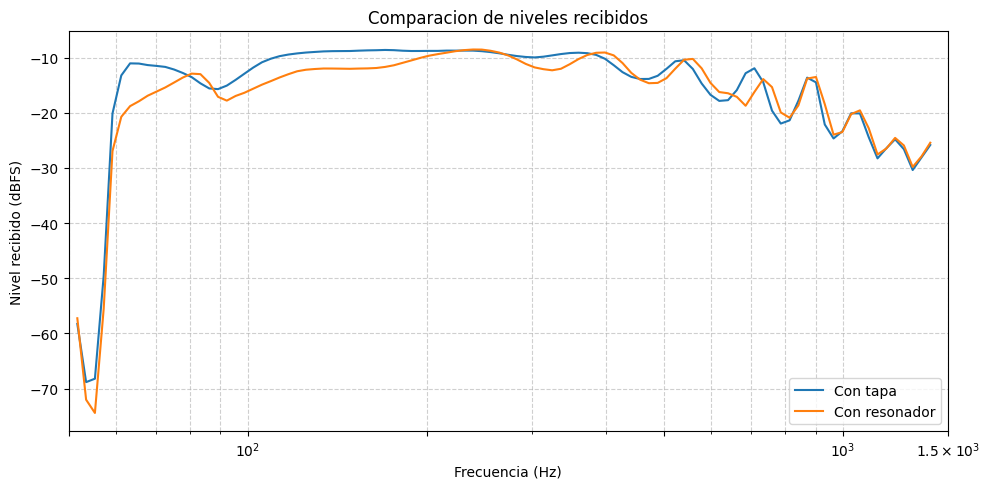

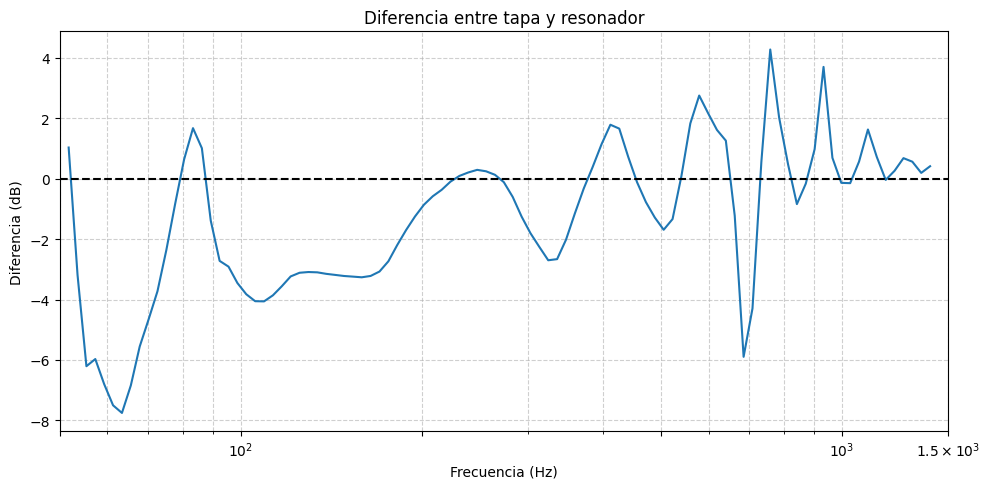


       COMPARACION FINALIZADA


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import sounddevice as sd
import os
from scipy.signal import chirp

# ==========================================================
# 1. CONFIGURACION
# ==========================================================

FS = 48000
DURACION = 5.0

F_INICIO = 50
F_FIN = 1500

AMPLITUD = 0.5

CANALES = 2
MIC = 0

REPETICIONES = 5

# MiniFuse 2
ENTRADA = 1
SALIDA = 7

# Seleccionar medicion
print("\n==========================================")
print("       MEDICION DE TUBO DE PVC")
print("==========================================")

print("1. Tapa")
print("2. Resonador")

opcion = input("\nSelecciona la medicion (1 o 2): ")

if opcion == "1":
    nombre = "tapa"

elif opcion == "2":
    nombre = "resonador"

else:
    print("Opcion incorrecta.")
    raise SystemExit

# ==========================================================
# 2. GENERAR BARRIDO
# ==========================================================

t = np.linspace(
    0,
    DURACION,
    int(FS * DURACION),
    endpoint=False
)

barrido = AMPLITUD * chirp(
    t,
    f0=F_INICIO,
    t1=DURACION,
    f1=F_FIN,
    method="logarithmic"
)

# Fade in y fade out
fade = int(FS * 0.05)

barrido[:fade] *= np.linspace(0, 1, fade)

barrido[-fade:] *= np.linspace(1, 0, fade)

# Señal estereo
barrido_estereo = np.column_stack((barrido, barrido))

# ==========================================================
# 3. MEDICION EXPERIMENTAL
# ==========================================================

print("\n==========================================")
print("          MEDICION EXPERIMENTAL")
print("==========================================")

print("Condicion:", nombre)
print("Frecuencia inicial:", F_INICIO, "Hz")
print("Frecuencia final:", F_FIN, "Hz")
print("Duracion:", DURACION, "segundos")
print("Repeticiones:", REPETICIONES)

input("\nPresiona ENTER para comenzar...")

grabaciones = []

for i in range(REPETICIONES):

    print("\nRealizando barrido", i + 1, "de", REPETICIONES)

    grabacion = sd.playrec(
        barrido_estereo,
        samplerate=FS,
        channels=CANALES,
        device=(ENTRADA, SALIDA),
        blocking=True
    )

    grabaciones.append(grabacion)

print("\nMediciones completadas.")

# Guardar mediciones
archivo = "grabaciones_" + nombre + ".npy"

np.save(archivo, np.array(grabaciones))

print("Datos guardados en:", archivo)

# ==========================================================
# 4. COMPROBAR SI EXISTEN LAS DOS MEDICIONES
# ==========================================================

if os.path.exists("grabaciones_tapa.npy") and os.path.exists("grabaciones_resonador.npy"):

    print("\nSe encontraron ambas mediciones.")
    print("Iniciando comparacion...")

    # Cargar mediciones
    tapa = np.load("grabaciones_tapa.npy")
    resonador = np.load("grabaciones_resonador.npy")

    # ======================================================
    # 5. CONFIGURACION DEL PROCESAMIENTO
    # ======================================================

    ventana = int(FS * 0.1)
    salto = int(ventana / 2)

    niveles_tapa = []
    niveles_resonador = []

    # ======================================================
    # 6. PROCESAR MEDICIONES CON TAPA
    # ======================================================

    for i in range(len(tapa)):

        microfono = tapa[i, :, MIC]

        rms_barrido = []

        for inicio in range(0, len(microfono) - ventana, salto):

            segmento = microfono[inicio:inicio + ventana]

            rms = np.sqrt(np.mean(segmento ** 2))

            rms_barrido.append(rms)

        niveles_tapa.append(rms_barrido)

    # ======================================================
    # 7. PROCESAR MEDICIONES CON RESONADOR
    # ======================================================

    for i in range(len(resonador)):

        microfono = resonador[i, :, MIC]

        rms_barrido = []

        for inicio in range(0, len(microfono) - ventana, salto):

            segmento = microfono[inicio:inicio + ventana]

            rms = np.sqrt(np.mean(segmento ** 2))

            rms_barrido.append(rms)

        niveles_resonador.append(rms_barrido)

    # ======================================================
    # 8. PROMEDIAR REPETICIONES
    # ======================================================

    promedio_tapa = np.mean(niveles_tapa, axis=0)

    promedio_resonador = np.mean(niveles_resonador, axis=0)

    # Convertir a decibeles
    db_tapa = 20 * np.log10(promedio_tapa + 1e-10)

    db_resonador = 20 * np.log10(promedio_resonador + 1e-10)

    # ======================================================
    # 9. RELACION TIEMPO - FRECUENCIA
    # ======================================================

    cantidad = len(promedio_tapa)

    tiempos = np.arange(cantidad) * salto / FS + ventana / (2 * FS)

    frecuencia = F_INICIO * (F_FIN / F_INICIO) ** (tiempos / DURACION)

    # ======================================================
    # 10. DIFERENCIA ENTRE MEDICIONES
    # ======================================================

    diferencia = db_resonador - db_tapa

    # ======================================================
    # 11. GRAFICA DE NIVELES RECIBIDOS
    # ======================================================

    plt.figure(figsize=(10, 5))

    plt.plot(frecuencia, db_tapa, label="Con tapa")

    plt.plot(frecuencia, db_resonador, label="Con resonador")

    plt.xscale("log")

    plt.xlim(50, 1500)

    plt.xticks([50, 100, 200, 500, 1000, 1500])

    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Nivel recibido (dBFS)")

    plt.title("Comparacion de niveles recibidos")

    plt.legend()

    plt.grid(True, which="both", linestyle="--", alpha=0.6)

    plt.tight_layout()

    plt.show()

    # ======================================================
    # 12. GRAFICA DE DIFERENCIA
    # ======================================================

    plt.figure(figsize=(10, 5))

    plt.plot(frecuencia, diferencia)

    plt.axhline(0, color="black", linestyle="--")

    plt.xscale("log")

    plt.xlim(50, 1500)

    plt.xticks([50, 100, 200, 500, 1000, 1500])

    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Diferencia (dB)")

    plt.title("Diferencia entre tapa y resonador")

    plt.grid(True, which="both", linestyle="--", alpha=0.6)

    plt.tight_layout()

    plt.show()

    # ======================================================
    # 13. GUARDAR RESULTADOS
    # ======================================================

    np.save("diferencia_resonador600.npy", diferencia)

    np.save("frecuencias600.npy", frecuencia)

    print("\n==========================================")
    print("       COMPARACION FINALIZADA")
    print("==========================================")

else:

    print("\nTodavia falta una medicion.")
    print("Ejecuta nuevamente el programa")
    print("y selecciona la otra condicion.")
